EXERCICE 3 : CNN sur MNIST

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd

In [12]:
# Étape 2 : Charger MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

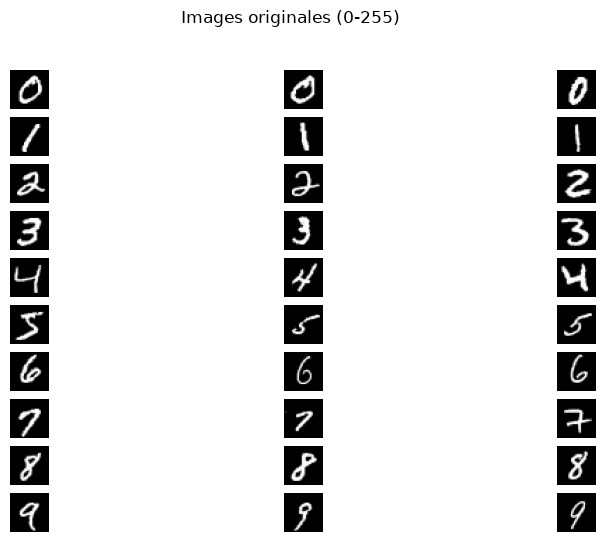

In [13]:
#Étape 3 : Visualiser quelques images
plt.figure(figsize=(10,6))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:3]
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit*3 + i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        plt.axis('off')
plt.suptitle("Images originales (0-255)")
plt.show()

In [14]:
#Étape 4 : Prétraitement — Normalisation
X_train = np.expand_dims(X_train_raw.astype("float32") / 255.0, - 1)
X_test = np.expand_dims(X_test_raw.astype("float32") / 255.0, - 1)
print("Formes finales :", X_train.shape,X_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [15]:
# Étape 6 : Construire le CNN
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [16]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Étape 8 : Entraîner est prise dans le train : le test reste inconnu jusqu'a l'évaluation final
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9223 - loss: 0.2506 - val_accuracy: 0.9852 - val_loss: 0.0482
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9797 - loss: 0.0703 - val_accuracy: 0.9857 - val_loss: 0.0518
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9846 - loss: 0.0524 - val_accuracy: 0.9882 - val_loss: 0.0404
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9884 - loss: 0.0412 - val_accuracy: 0.9857 - val_loss: 0.0467
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9902 - loss: 0.0317 - val_accuracy: 0.9867 - val_loss: 0.0465


In [18]:
# Étape 9 : Évaluer sur le test
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}%")

313/313 - 2s - 7ms/step - accuracy: 0.9882 - loss: 0.0402

Précision sur le test: 98.82%


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


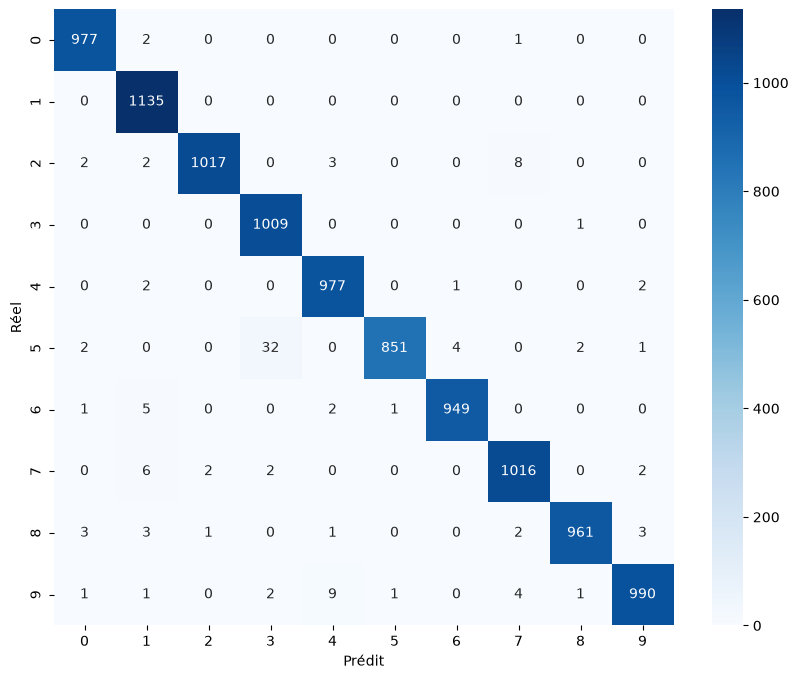

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.98      1.00      0.99      1135
           2       1.00      0.99      0.99      1032
           3       0.97      1.00      0.98      1010
           4       0.98      0.99      0.99       982
           5       1.00      0.95      0.98       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [19]:
y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

print(classification_report(y_test, y_pred))

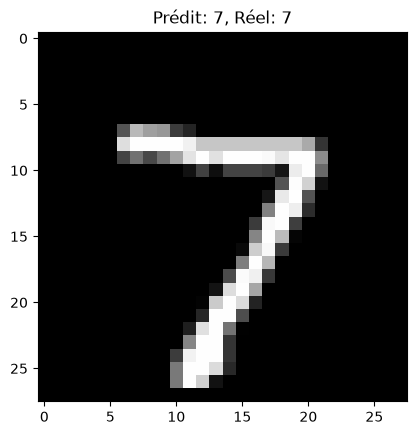

In [20]:
plt.imshow(X_test[0].reshape(28,28), cmap="gray")
plt.title(f"Prédit: {y_pred[0]}, Réel: {y_test[0]}")
plt.show()